In [9]:
import xarray as xr
import xroms 

In [24]:
ds = xr.open_dataset('/scratch/ss4338/Project/Moana-2.0/Apps/moana/Input/moana_grid.nc')

ds2 = xr.open_dataset('/scratch/ss4338/Project/Moana-2.0/Apps/moana/Input/moana_grid.nc')

In [47]:
ds

<xarray.Dataset> Size: 50MB
Dimensions:      (s_rho: 40, s_w: 41, eta_rho: 467, xi_rho: 397, bath: 1,
                  eta_u: 467, xi_u: 396, eta_v: 466, xi_v: 397, eta_psi: 466,
                  xi_psi: 396, eta_vert: 468, xi_vert: 398)
Coordinates:
  * s_rho        (s_rho) float64 320B -0.9799 -0.9403 ... -0.01529 -0.004904
  * s_w          (s_w) float64 328B -1.0 -0.96 -0.9208 ... -0.02077 -0.01 0.0
    lon_rho      (eta_rho, xi_rho) float64 1MB ...
    lat_rho      (eta_rho, xi_rho) float64 1MB ...
Dimensions without coordinates: eta_rho, xi_rho, bath, eta_u, xi_u, eta_v,
                                xi_v, eta_psi, xi_psi, eta_vert, xi_vert
Data variables: (12/44)
    theta_s      int64 8B 7
    theta_b      int64 8B 2
    Tcline       int64 8B 250
    hc           float64 8B ...
    Cs_r         (s_rho) float64 320B ...
    Cs_w         (s_w) float64 328B ...
    ...           ...
    mask_psi     (eta_psi, xi_psi) float64 1MB ...
    visc_factor  (eta_rho, xi_rho) float64 1MB ...
    diff_factor  (eta_rho, xi_rho) float64 1MB ...
    Vtransform   int64 8B 2
    Vstretching  int64 8B 4
    zeta         int64 8B 0
Attributes:
    Description:  ROMS grid
    Author:       pyroms.grid.write_grd
    Created:      2019-01-07T11:37:30.512859
    type:         ROMS grid file

In [43]:
ds['Vtransform'] = 2
ds['Vstretching'] =4
ds['Tcline'] = 250
ds['zeta'] = 0
ds['theta_s'] = 7
ds['theta_b'] = 2

ds2['Vtransform'] = 2
ds2['Vstretching'] =5
ds2['Tcline'] = 250
ds2['zeta'] = 0


In [44]:
da, xgrid = xroms.roms_dataset(ds)
da.xroms.set_grid(xgrid)

da2, xgrid2 = xroms.roms_dataset(ds2)
da2.xroms.set_grid(xgrid2)

/home/ss4338/miniconda3/envs/chapter1/lib/python3.11/site-packages/xgcm/grid_ufunc.py:832: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  out_dim: grid._ds.dims[out_dim] for arg in out_core_dims for out_dim in arg
/home/ss4338/miniconda3/envs/chapter1/lib/python3.11/site-packages/xgcm/grid_ufunc.py:832: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  out_dim: grid._ds.dims[out_dim] for arg in out_core_dims for out_dim in arg
/home/ss4338/miniconda3/envs/chapter1/lib/python3.11/site-packages/xgcm/grid_ufunc.py:832: FutureWarning: The return type of `Dataset.dims` will be changed to return a se

Text(0.5, 1.0, 'ROMS ECCOFS s-layers, eta_rho=130')

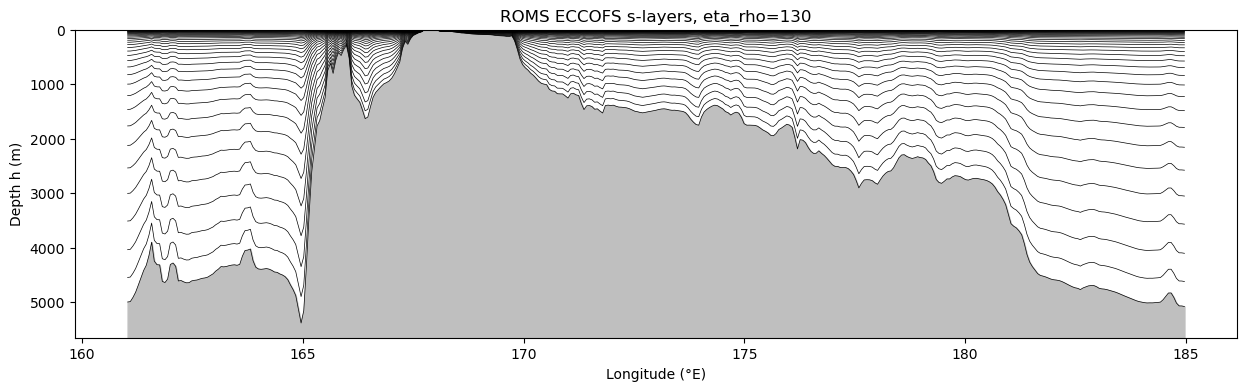

In [45]:
import matplotlib.pyplot as plt

j   = 130                                   # eta_rho index of the section
lon = da.lon_rho.isel(eta_rho=j)
zw  = da.z_w.isel(eta_rho=j)                # (s_w, xi_rho), negative down
h   = da.h.isel(eta_rho=j)

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(lon, -zw.values.T, color="k", lw=0.5)                     # s-level interfaces as depth
ax.fill_between(lon, h, h.max() * 1.05, color="0.75")     # seafloor
ax.set_ylim(h.max() * 1.05, 0)                         # surface on top
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Depth h (m)")
ax.set_title(f"ROMS ECCOFS s-layers, eta_rho={j}")

Text(0.5, 1.0, 'ROMS MOANA s-layers, eta_rho=130')

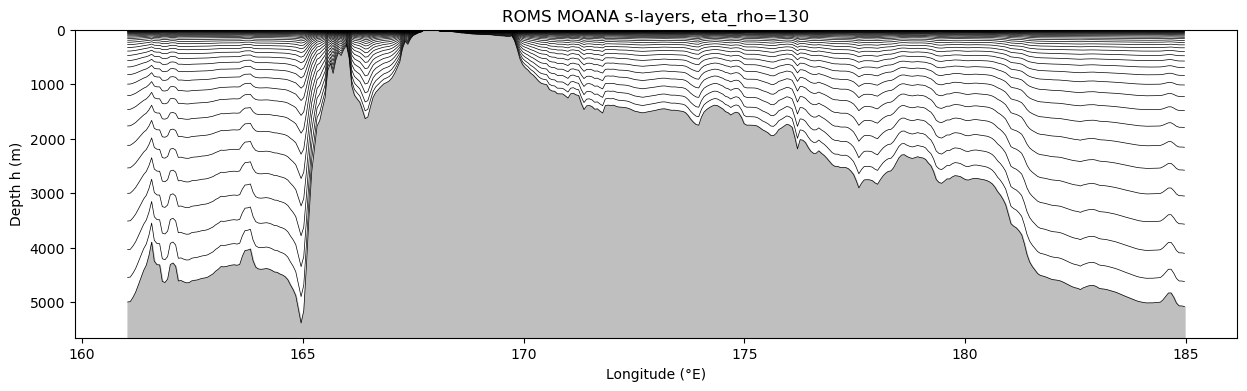

In [46]:
j   = 130                                   # eta_rho index of the section
lon = da2.lon_rho.isel(eta_rho=j)
zw  = da2.z_w.isel(eta_rho=j)              # (s_w, xi_rho), negative down
h   = da2.h.isel(eta_rho=j)

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(lon, -zw.values.T, color="k", lw=0.5)          # s-level interfaces as depth
ax.fill_between(lon, h, h.max() * 1.05, color="0.75")  # seafloor
ax.set_ylim(h.max() * 1.05, 0)                         # surface on top
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Depth h (m)")
ax.set_title(f"ROMS MOANA s-layers, eta_rho={j}")

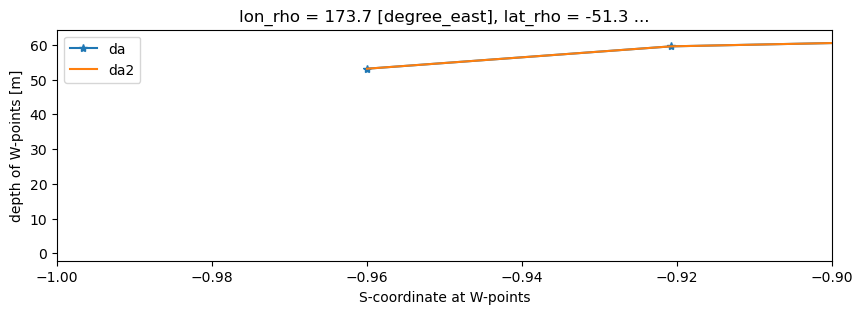

In [75]:
fig, ax = plt.subplots(figsize=(10, 3))
da.z_w.isel(xi_rho=210, eta_rho=18).diff('s_w').plot(marker='*', ax=ax, label='da')
da2.z_w.isel(xi_rho=210, eta_rho=18).diff('s_w').plot(ax=ax, label='da2')
ax.set_xlim(-1, -0.9)
ax.legend()

In [ ]:
G1 = da.z_w.isel(xi_rho=210, eta_rho=18).diff('s_w')

G2 = da2.z_w.isel(xi_rho=210, eta_rho=18).diff('s_w')